# Proyecto Profesional: Modelamiento de Riesgo Crediticio con IA (ML & DL)
## Clasificación Imbalanceada para la Predicción de Default (`FLG_CLI_DEF60`)

---

### **Metadatos Institucionales (Instituto Continental)**
* **Estudiante:** **Christian Henry Casso Quispe** (Código: `i2513568`)
* **Docente:** **Max Walter Alonzo Huamán**
* **Unidad Didáctica:** Lógica para la Inteligencia Artificial
* **Repositorio Oficial de GitHub:** [https://github.com/i2513568-ALESTI/LIA_IDL03](https://github.com/i2513568-ALESTI/LIA_IDL03)
* **Fecha:** Noviembre de 2026

---

### **Información del Proyecto**
* **Temas Evaluados:**
  1. *Programación de la lógica de algoritmos IA.*
  2. *Integración de la lógica en frameworks de IA (XGBoost & PyTorch).*
  3. *Validación y prueba de algoritmos implementados.*
* **Indicador de Logro 3:** *Implementa la lógica de algoritmos de IA en función de soluciones prácticas en proyectos de ciencia de datos.*
* **Tipo de Caso Práctico:** Informe de implementación de un problema de ciencia de datos usando Machine Learning (ML) y Deep Learning (DL).

---

### **Contexto de Negocio y Desafío Crediticio**
En una institución bancaria de primer nivel, la Gerencia de Riesgos y el equipo de Políticas Crediticias tienen como objetivo prioritario evaluar el nivel de riesgo de la cartera de clientes. El fin es direccionar las políticas de originación y seguimiento crediticio: **mayor rigurosidad y exigencia en clientes de alto riesgo** y **mayor agilidad y condiciones favorables en clientes de bajo riesgo**.

* **Definición de Default (`FLG_CLI_DEF60`):** Comportamiento de pago en una ventana de desempeño de 12 meses posteriores a la fecha de observación. Si durante dicho período el atraso máximo del cliente supera o iguala el umbral de **60 días**, el cliente se etiqueta como Default (`FLG_CLI_DEF60 = 1`), caso contrario `0`.
* **Requerimiento Especial de Políticas:** El equipo de Políticas destacó la necesidad de analizar el atraso histórico y evaluar el comportamiento diferencial entre clientes **con atrasos** y **sin atrasos** en su historial.
* **Datos:** Stock de clientes entre 201701 y 201803 (50,591 registros) con 10 variables predictivas preseleccionadas de información interna y del buró financiero (RCC), consolidadas en `base10.csv` con su respectivo `DICCIONARIO.xlsx`.

---


## 1. Configuración del Entorno y Carga de Datos

En esta etapa inicial importamos las bibliotecas fundamentales del ecosistema científico de Python (`pandas`, `numpy`, `scipy`, `matplotlib`, `seaborn`, `sklearn`), el framework líder de árboles potenciados por gradiente (`xgboost`) y el framework de Deep Learning de nivel de producción (`torch` - PyTorch).

Asimismo, cargamos el dataset `base10.csv` y parseamos dinámicamente el diccionario de variables desde `DICCIONARIO.xlsx` para disponer de la semántica de negocio de cada variable durante todo el análisis.


In [1]:
import os
import sys
import zipfile
import xml.etree.ElementTree as ET
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Scikit-Learn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report, brier_score_loss, f1_score, recall_score, precision_score
)

# Frameworks de IA
import xgboost as xgb
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

# Fijar semillas para reproducibilidad total
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Versión de Python    : {sys.version.split()[0]}")
print(f"Versión de XGBoost   : {xgb.__version__}")
print(f"Versión de PyTorch   : {torch.__version__}")
print(f"Dispositivo PyTorch  : {'CUDA (GPU)' if torch.cuda.is_available() else 'CPU'}")

# 1. Cargar el dataset base10.csv
df = pd.read_csv('base10.csv')
print(f"\nDataset 'base10.csv' cargado exitosamente. Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas.")

# 2. Parsear el DICCIONARIO.xlsx
dict_rows = []
if os.path.exists('DICCIONARIO.xlsx'):
    try:
        with zipfile.ZipFile('DICCIONARIO.xlsx', 'r') as z:
            shared_strings = []
            if 'xl/sharedStrings.xml' in z.namelist():
                tree = ET.fromstring(z.read('xl/sharedStrings.xml'))
                for elem in tree.iter('{http://schemas.openxmlformats.org/spreadsheetml/2006/main}t'):
                    shared_strings.append(elem.text)
            
            sheet_xml = z.read('xl/worksheets/sheet1.xml')
            tree = ET.fromstring(sheet_xml)
            ns = {'ns': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
            for row in tree.findall('.//ns:row', ns):
                r_vals = []
                for c in row.findall('ns:c', ns):
                    t = c.attrib.get('t')
                    v = c.find('ns:v', ns)
                    val = v.text if v is not None else ''
                    if t == 's' and val:
                        val = shared_strings[int(val)]
                    r_vals.append(val)
                if r_vals:
                    dict_rows.append(r_vals)
    except Exception as e:
        print(f"Nota sobre diccionario: {e}")

df_diccionario = pd.DataFrame(dict_rows[1:], columns=dict_rows[0]) if len(dict_rows) > 1 else pd.DataFrame()

# Mostrar catálogo de variables en base10.csv
cols_in_data = list(df.columns)
catalogo = df_diccionario[df_diccionario['CAMPO'].isin(cols_in_data)].reset_index(drop=True)
pd.set_option('display.max_colwidth', None)
print("\n--- CATÁLOGO DE VARIABLES SELECCIONADAS (base10.csv) ---")
display(catalogo)


Versión de Python    : 3.12.3
Versión de XGBoost   : 3.4.1
Versión de PyTorch   : 2.12.0+cpu
Dispositivo PyTorch  : CPU

Dataset 'base10.csv' cargado exitosamente. Dimensiones: 50591 filas x 11 columnas.

--- CATÁLOGO DE VARIABLES SELECCIONADAS (base10.csv) ---
                       CAMPO                                                                                                                                                    DESCRIPCIÓN
0              FLG_CLI_DEF60                                                                                                                                                        Default
1     INC_SUM_ACTSH_ACTU_24M              INCREMENTO DE DEUDA ACTIVA S/HIP. (CONSIDERANDO SUMA)||Total deuda activa s/hip. en los últimos 24 meses respecto a la deuda activa s/hip. actual
2              MAX_ATR_I_12M                                                                                                                MAX_ATR||Máximo atrasos en los últ

## 2. Análisis Exploratorio de Datos (EDA) y Hallazgos de Negocio

El análisis exploratorio en riesgo crediticio no solo debe verificar la integridad matemática de los datos, sino también responder a las preguntas estratégicas del negocio:
1. **Magnitud del Desbalance:** ¿Qué porcentaje de clientes incurre en default y cuál es la tasa base de eventos?
2. **Hipótesis del Equipo de Políticas:** ¿Existe una separación empírica real entre los clientes que presentan antecedentes de atraso frente a los que no tienen atrasos en su historia?
3. **Calidad de Datos y Outliers Extremos:** ¿Existen valores aberrantes o denominadores cercanos a cero en los ratios financieros que puedan distorsionar el entrenamiento de la Red Neuronal?


--- 1. DIAGNÓSTICO DE INTEGRIDAD ---
Total de valores nulos en el dataset: 0
Registros duplicados: 1

--- 2. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (FLG_CLI_DEF60) ---
Clientes Buenos (0) : 45,176 (89.30%)
Clientes Malos (1)  : 5,415 (10.70%)
Ratio de Desbalance : 8.34 a 1 (Negativos por cada Positivo)

--- 3. HALLAZGO CLAVE PARA EL EQUIPO DE POLÍTICAS ---
Clientes SIN atraso en 12M: 8,820 (17.43%) | Tasa de Default: 2.34%
Clientes CON atraso en 12M: 41,771 (82.57%) | Tasa de Default: 12.47%
-> Un cliente con historial de atraso es 5.3 veces más propenso a caer en Default.

--- 4. DIAGNÓSTICO DE VALORES EXTREMOS / OUTLIERS ---
                               min        1%        50%        95%         99%       99.5%           max
MAX_ATR_I_12M             0.000000  0.000000   3.000000  29.000000   51.000000   57.000000  1.034000e+03
NMES_ATR15_I_U6K_24M      0.000000  0.000000   0.000000   2.000000    5.000000    6.000000  6.000000e+00
RTOT_DACT_DTOT_24M        0.006823  0.246572   0.959

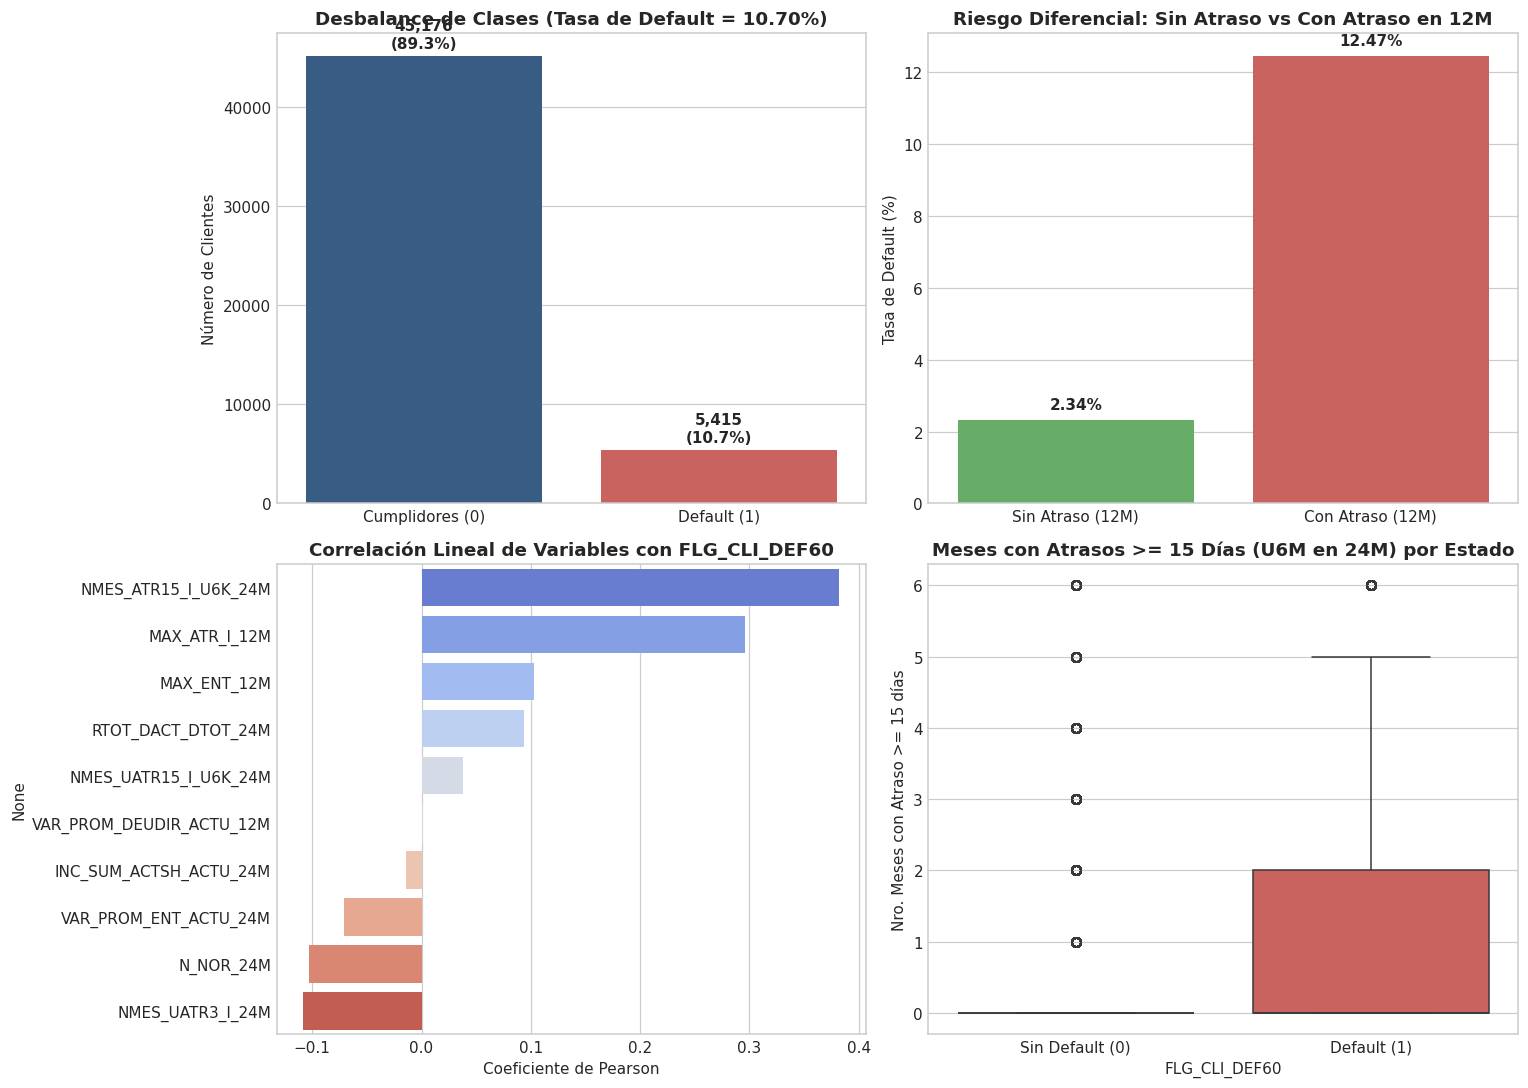

In [2]:
# 1. Diagnóstico de valores nulos y tipos
print("--- 1. DIAGNÓSTICO DE INTEGRIDAD ---")
nulos = df.isnull().sum()
print(f"Total de valores nulos en el dataset: {nulos.sum()}")
print(f"Registros duplicados: {df.duplicated().sum()}")

# 2. Análisis del Desbalance de la Clase Objetivo
conteo_target = df['FLG_CLI_DEF60'].value_counts()
pct_target = df['FLG_CLI_DEF60'].value_counts(normalize=True) * 100
imbalance_ratio = conteo_target[0] / conteo_target[1]

print("\n--- 2. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO (FLG_CLI_DEF60) ---")
print(f"Clientes Buenos (0) : {conteo_target[0]:,d} ({pct_target[0]:.2f}%)")
print(f"Clientes Malos (1)  : {conteo_target[1]:,d} ({pct_target[1]:.2f}%)")
print(f"Ratio de Desbalance : {imbalance_ratio:.2f} a 1 (Negativos por cada Positivo)")

# 3. HALLAZGO CLAVE DEL NEGOCIO: Segmentación por Historial de Atraso (Solicitud de Políticas)
sin_atraso_12m = df[df['MAX_ATR_I_12M'] == 0]
con_atraso_12m = df[df['MAX_ATR_I_12M'] > 0]

tasa_sin_atraso = sin_atraso_12m['FLG_CLI_DEF60'].mean() * 100
tasa_con_atraso = con_atraso_12m['FLG_CLI_DEF60'].mean() * 100
ratio_riesgo_atraso = tasa_con_atraso / tasa_sin_atraso

print("\n--- 3. HALLAZGO CLAVE PARA EL EQUIPO DE POLÍTICAS ---")
print(f"Clientes SIN atraso en 12M: {len(sin_atraso_12m):,d} ({len(sin_atraso_12m)/len(df):.2%}) | Tasa de Default: {tasa_sin_atraso:.2f}%")
print(f"Clientes CON atraso en 12M: {len(con_atraso_12m):,d} ({len(con_atraso_12m)/len(df):.2%}) | Tasa de Default: {tasa_con_atraso:.2f}%")
print(f"-> Un cliente con historial de atraso es {ratio_riesgo_atraso:.1f} veces más propenso a caer en Default.")

# 4. Diagnóstico de Outliers Extremos en Ratios Financieros
stats_df = df.describe(percentiles=[0.01, 0.5, 0.95, 0.99, 0.995]).T[['min', '1%', '50%', '95%', '99%', '99.5%', 'max']]
print("\n--- 4. DIAGNÓSTICO DE VALORES EXTREMOS / OUTLIERS ---")
display(stats_df)

# Visualización del EDA
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: Desbalance de Clases
sns.barplot(x=['Cumplidores (0)', 'Default (1)'], y=conteo_target.values, palette=['#2b5c8f', '#d9534f'], ax=axes[0, 0])
axes[0, 0].set_title(f'Desbalance de Clases (Tasa de Default = {pct_target[1]:.2f}%)', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Número de Clientes')
for i, v in enumerate(conteo_target.values):
    axes[0, 0].text(i, v + 800, f"{v:,d}\n({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# Gráfico 2: Tasa de Default según Atraso en 12M
sns.barplot(x=['Sin Atraso (12M)', 'Con Atraso (12M)'], y=[tasa_sin_atraso, tasa_con_atraso], palette=['#5cb85c', '#d9534f'], ax=axes[0, 1])
axes[0, 1].set_title('Riesgo Diferencial: Sin Atraso vs Con Atraso en 12M', fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('Tasa de Default (%)')
for i, v in enumerate([tasa_sin_atraso, tasa_con_atraso]):
    axes[0, 1].text(i, v + 0.3, f"{v:.2f}%", ha='center', fontweight='bold')

# Gráfico 3: Matriz de Correlación con la Variable Objetivo
corr = df.corr()
target_corr = corr[['FLG_CLI_DEF60']].sort_values(by='FLG_CLI_DEF60', ascending=False)
sns.barplot(x=target_corr['FLG_CLI_DEF60'].values[1:], y=target_corr.index[1:], palette='coolwarm', ax=axes[1, 0])
axes[1, 0].set_title('Correlación Lineal de Variables con FLG_CLI_DEF60', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Coeficiente de Pearson')

# Gráfico 4: Distribución de Meses de Atraso >= 15 días según Default
sns.boxplot(x='FLG_CLI_DEF60', y='NMES_ATR15_I_U6K_24M', data=df, palette=['#2b5c8f', '#d9534f'], ax=axes[1, 1])
axes[1, 1].set_title('Meses con Atrasos >= 15 Días (U6M en 24M) por Estado', fontsize=12, fontweight='bold')
axes[1, 1].set_xticklabels(['Sin Default (0)', 'Default (1)'])
axes[1, 1].set_ylabel('Nro. Meses con Atraso >= 15 días')

plt.tight_layout()
plt.show()


## 3. Preprocesamiento Profesional y Estrategia de Validación

### **Tratamiento Crítico de Outliers y Asimetría:**
Durante el diagnóstico observamos que la variable `INC_SUM_ACTSH_ACTU_24M` presenta un valor máximo de **5,555,555,555.00** (5.5 mil millones), producto de divisiones por deuda actual nula o codificación de flags de ratio infinito en buró. Asimismo, `VAR_PROM_DEUDIR_ACTU_12M` alcanza valores superiores a 1,754.

* **Impacto en XGBoost:** Los árboles de decisión se basan en particiones por umbral ($x_j \le 	heta$), por lo que son invariantes a transformaciones monótonas y resistentes a outliers.
* **Impacto en Redes Neuronales:** Las redes neuronales calculan combinaciones lineales $z = Wx + b$. Si una sola variable tiene valores del orden de $10^9$, su media y desviación estándar se distorsionan completamente bajo un `StandardScaler` ordinario, provocando la saturación de gradientes (*vanishing/exploding gradients*) e invalidando el aprendizaje de las neuronas.
* **Solución Profesional:** Aplicamos **Winsorización al percentil 99.5%** sobre las variables de cola pesada y empleamos `RobustScaler` / estandarización cuidada para alimentar la Red Neuronal.

### **Estrategia de Partición y Manejo del Desbalance:**
1. **Partición Estratificada (80% Train, 20% Test):** Mantiene la proporción idéntica de clientes en default (10.70%) en ambos conjuntos, evitando sesgos de selección.
2. **Ponderación de Clases (`scale_pos_weight`):**
   $$\text{scale\_pos\_weight} = \frac{N_{\text{negativos}}}{N_{\text{positivos}}} = \frac{36,140}{4,332} \approx 8.343$$
   Este multiplicador penaliza el error en la clase minoritaria por un factor de ~8.34 veces, garantizando que el optimizador priorice la detección de los clientes en riesgo.


In [3]:
# 1. Separar matriz de características (X) y vector objetivo (y)
X_raw = df.drop(columns=['FLG_CLI_DEF60'])
y = df['FLG_CLI_DEF60'].astype(int)

# 2. Winsorización al percentil 99.5% en variables con colas pesadas
X_clean = X_raw.copy()
outlier_cols = ['INC_SUM_ACTSH_ACTU_24M', 'VAR_PROM_DEUDIR_ACTU_12M', 'MAX_ATR_I_12M']
capping_dict = {}

for col in outlier_cols:
    cap_value = X_clean[col].quantile(0.995)
    capping_dict[col] = cap_value
    X_clean[col] = np.clip(X_clean[col], None, cap_value)

print("--- TOP-CAPPING APLICADO (Percentil 99.5%) ---")
for col, val in capping_dict.items():
    print(f"Variable '{col}': umbral de corte = {val:.2f}")

# 3. Partición Estratificada Train/Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y, test_size=0.20, random_state=SEED, stratify=y
)

print(f"\nConjunto de Entrenamiento : {X_train.shape[0]:,d} registros (Tasa Default: {y_train.mean():.2%})")
print(f"Conjunto de Evaluación    : {X_test.shape[0]:,d} registros (Tasa Default: {y_test.mean():.2%})")

# 4. Cálculo del factor de compensación de desbalance
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_val = neg_count / pos_count
print(f"\nPeso de balanceo calculado (scale_pos_weight) = {scale_pos_weight_val:.4f}")

# 5. Escalado Robusto para la Red Neuronal
scaler_nn = RobustScaler()
X_train_scaled = scaler_nn.fit_transform(X_train)
X_test_scaled = scaler_nn.transform(X_test)

print("Escalado RobustScaler aplicado satisfactoriamente para la Red Neuronal.")


--- TOP-CAPPING APLICADO (Percentil 99.5%) ---
Variable 'INC_SUM_ACTSH_ACTU_24M': umbral de corte = 237.52
Variable 'VAR_PROM_DEUDIR_ACTU_12M': umbral de corte = 4.84
Variable 'MAX_ATR_I_12M': umbral de corte = 57.00

Conjunto de Entrenamiento : 40,472 registros (Tasa Default: 10.70%)
Conjunto de Evaluación    : 10,119 registros (Tasa Default: 10.70%)

Peso de balanceo calculado (scale_pos_weight) = 8.3426
Escalado RobustScaler aplicado satisfactoriamente para la Red Neuronal.


## 4. Implementación y Entrenamiento: Algoritmo 1 - XGBoost (Gradient Boosting)

### **Fundamento Matemático del Algoritmo:**
XGBoost minimiza una función objetivo regularizada en el paso $t$:
$$\mathcal{L}^{(t)} = \sum_{i=1}^n l\left(y_i, \hat{y}_i^{(t-1)} + f_t(x_i)\right) + \Omega(f_t)$$
donde $\Omega(f) = \gamma T + \frac{1}{2} \lambda \sum_{j=1}^T w_j^2$ controla la complejidad del árbol. Utilizando una aproximación de Taylor de segundo orden:
$$\mathcal{L}^{(t)} \approx \sum_{i=1}^n \left[ g_i f_t(x_i) + \frac{1}{2} h_i f_t^2(x_i) \right] + \Omega(f_t)$$
donde $g_i$ y $h_i$ son el gradiente y el hessiano de la función de pérdida logística.

### **Integración del Desbalance en XGBoost:**
El parámetro `scale_pos_weight` multiplica los gradientes y hessianos de la clase positiva:
$$g_i = \text{scale\_pos\_weight} \cdot (p_i - 1), \quad h_i = \text{scale\_pos\_weight} \cdot p_i(1 - p_i) \quad \forall y_i = 1$$
Esto incrementa la ganancia de división (*split gain*) cuando una hoja aísla observaciones en riesgo de default.


=== ENTRENAMIENTO DE XGBOOST CLASSIFIER ===
Rendimiento XGBoost en Test:
 -> ROC-AUC  : 0.8297
 -> GINI     : 0.6593
 -> PR-AUC   : 0.5067

Top 5 Drivers de Riesgo según XGBoost:
 - NMES_ATR15_I_U6K_24M: N_MESES_ATR||Número de meses con atrasos mayores iguales a 15 en los últimos 6 meses de comportamiento en los últimos 24 meses (Gain: 389.65)
 - MAX_ATR_I_12M: MAX_ATR||Máximo atrasos en los últimos 12 meses (Gain: 304.91)
 - NMES_UATR3_I_24M: N_MESES_UATR||Número de meses desde el último atraso mayor o igual a 3 días de atraso observado en los 24 últimos meses (distancia) (Gain: 77.19)
 - INC_SUM_ACTSH_ACTU_24M: INCREMENTO DE DEUDA ACTIVA S/HIP. (CONSIDERANDO SUMA)||Total deuda activa s/hip. en los últimos 24 meses respecto a la deuda activa s/hip. actual (Gain: 49.13)
 - MAX_ENT_12M: MÁXIMA CANTIDAD DE ENTIDADES ACREEDORAS||Nro. máximo de entidades acreedoras en los últimos 12 meses (Gain: 47.09)


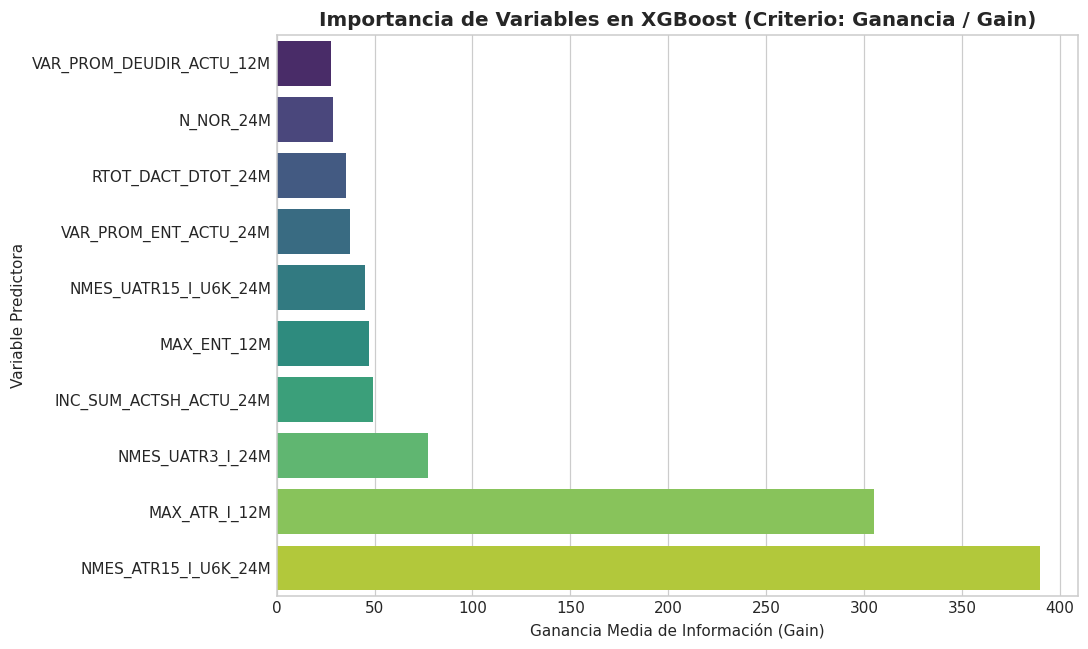

In [4]:
print("=== ENTRENAMIENTO DE XGBOOST CLASSIFIER ===")

# Configuración del estimador XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=350,
    learning_rate=0.04,
    max_depth=4,
    min_child_weight=3,
    subsample=0.85,
    colsample_bytree=0.85,
    scale_pos_weight=scale_pos_weight_val,
    objective='binary:logistic',
    eval_metric='aucpr',
    random_state=SEED,
    n_jobs=-1
)

# Entrenamiento con Early Stopping monitoreando la curva Precision-Recall (aucpr)
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

# Predicción de probabilidades y etiquetas binarias
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]
y_pred_xgb_default = (y_prob_xgb >= 0.50).astype(int)

# Métricas clave
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)
pr_auc_xgb = average_precision_score(y_test, y_prob_xgb)
gini_xgb = 2 * roc_auc_xgb - 1

print(f"Rendimiento XGBoost en Test:")
print(f" -> ROC-AUC  : {roc_auc_xgb:.4f}")
print(f" -> GINI     : {gini_xgb:.4f}")
print(f" -> PR-AUC   : {pr_auc_xgb:.4f}")

# Importancia de Variables (Feature Importance por Ganancia)
importance_gain = xgb_model.get_booster().get_score(importance_type='gain')
df_importance = pd.DataFrame({
    'Feature': list(importance_gain.keys()),
    'Gain': list(importance_gain.values())
}).sort_values(by='Gain', ascending=True)

# Mapear descripciones del diccionario
dict_map = dict(zip(df_diccionario['CAMPO'], df_diccionario['DESCRIPCIÓN'])) if not df_diccionario.empty else {}
df_importance['Description'] = df_importance['Feature'].map(dict_map).fillna(df_importance['Feature'])

# Visualización de la Importancia de Variables
plt.figure(figsize=(10, 6))
sns.barplot(x='Gain', y='Feature', data=df_importance, palette='viridis')
plt.title('Importancia de Variables en XGBoost (Criterio: Ganancia / Gain)', fontsize=13, fontweight='bold')
plt.xlabel('Ganancia Media de Información (Gain)')
plt.ylabel('Variable Predictora')
plt.tight_layout()
plt.show()

print("\nTop 5 Drivers de Riesgo según XGBoost:")
for idx, r in df_importance.tail(5).iloc[::-1].iterrows():
    print(f" - {r['Feature']}: {r['Description']} (Gain: {r['Gain']:.2f})")


## 5. Implementación y Entrenamiento: Algoritmo 2 - Red Neuronal Profunda Tabular (PyTorch)

### **Diseño de la Arquitectura Deep Learning Tabular:**
Para datos tabulares desbalanceados en banca, una arquitectura Feedforward con conexiones residuales (**Tabular ResNet**) ofrece ventajas superiores frente a un MLP simple:
1. **Batch Normalization (`nn.BatchNorm1d`):** Reduce el desplazamiento covariable interno (*internal covariate shift*), estabilizando el paso hacia adelante y acelerando la convergencia.
2. **Bloque Residual (Skip Connection):** Permite que el gradiente fluya sin atenuación a través de la identidad $x + \mathcal{F}(x)$, capturando interacciones no lineales de alto orden entre ratios de deuda y días de atraso.
3. **Dropout Regularization:** Previene la co-adaptación excesiva de las neuronas en una base con 89% de ejemplos negativos.
4. **Función de Pérdida Ponderada (`BCEWithLogitsLoss` con `pos_weight`):**
   $$\mathcal{L}_{\text{BCE}}(x, y) = - \sum_{i} \left[ w_{\text{pos}} \cdot y_i \log \sigma(x_i) + (1 - y_i) \log(1 - \sigma(x_i)) \right]$$
   Al integrar la activación Sigmoid dentro de la pérdida de forma analítica con la formulación log-sum-exp, se garantiza una alta estabilidad numérica y se evita el subdesbordamiento aritmético (*underflow*).


=== ARQUITECTURA E INTEGRACIÓN EN PYTORCH ===
Entrenando modelo PyTorch en: cpu
Epoch [01/35] - Loss: 0.9386 | Val Loss: 0.9231 | Val ROC-AUC: 0.8213 | Val PR-AUC: 0.4848
Epoch [05/35] - Loss: 0.8925 | Val Loss: 0.9091 | Val ROC-AUC: 0.8259 | Val PR-AUC: 0.4971
Epoch [10/35] - Loss: 0.8825 | Val Loss: 0.9081 | Val ROC-AUC: 0.8263 | Val PR-AUC: 0.4988
Epoch [15/35] - Loss: 0.8814 | Val Loss: 0.9068 | Val ROC-AUC: 0.8261 | Val PR-AUC: 0.5003
Epoch [20/35] - Loss: 0.8776 | Val Loss: 0.9042 | Val ROC-AUC: 0.8276 | Val PR-AUC: 0.5014
Epoch [25/35] - Loss: 0.8731 | Val Loss: 0.9061 | Val ROC-AUC: 0.8273 | Val PR-AUC: 0.5022
Epoch [30/35] - Loss: 0.8685 | Val Loss: 0.9051 | Val ROC-AUC: 0.8279 | Val PR-AUC: 0.5018
Epoch [35/35] - Loss: 0.8708 | Val Loss: 0.9033 | Val ROC-AUC: 0.8283 | Val PR-AUC: 0.5039

Rendimiento Final Red Neuronal Tabular:
 -> ROC-AUC  : 0.8283
 -> GINI     : 0.6566
 -> PR-AUC   : 0.5039


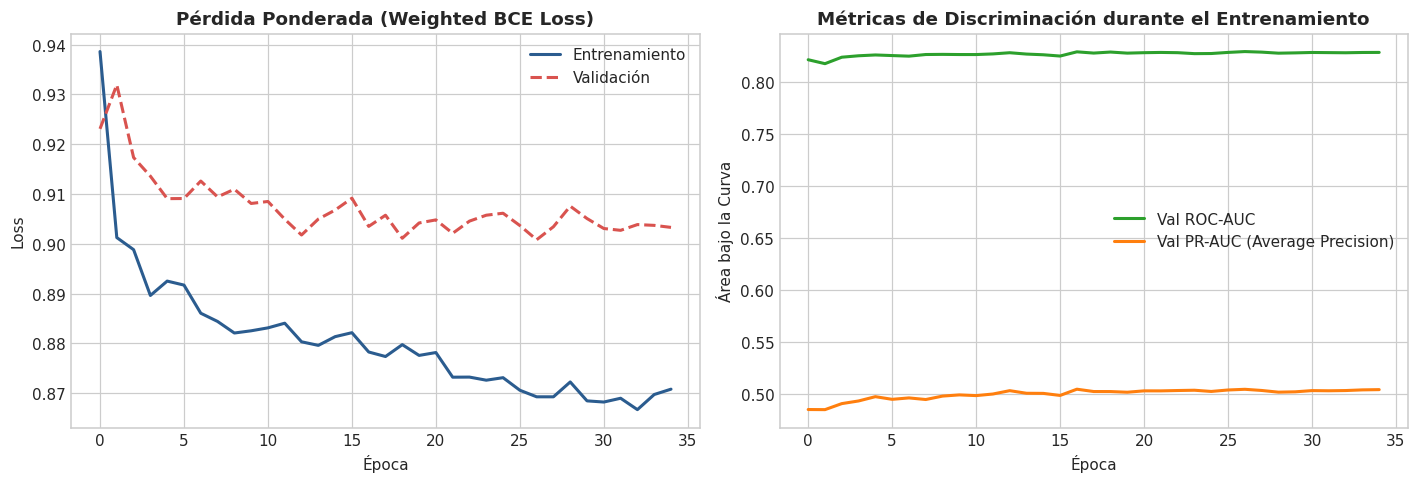

In [5]:
print("=== ARQUITECTURA E INTEGRACIÓN EN PYTORCH ===")

# Definición del Modelo Tabular con Conexión Residual
class TabularResNet(nn.Module):
    def __init__(self, in_features):
        super(TabularResNet, self).__init__()
        # Capa de entrada con proyección
        self.input_layer = nn.Sequential(
            nn.Linear(in_features, 64),
            nn.BatchNorm1d(64),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.25)
        )
        
        # Bloque Residual
        self.res_block = nn.Sequential(
            nn.Linear(64, 64),
            nn.BatchNorm1d(64),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.25),
            nn.Linear(64, 64),
            nn.BatchNorm1d(64)
        )
        self.res_activation = nn.LeakyReLU(0.1)
        
        # Capa densa intermedia
        self.dense = nn.Sequential(
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.Dropout(0.20)
        )
        
        # Capa de salida (Logits)
        self.out_layer = nn.Linear(32, 1)
        
    def forward(self, x):
        h0 = self.input_layer(x)
        h_res = self.res_activation(h0 + self.res_block(h0)) # Skip connection
        h1 = self.dense(h_res)
        logits = self.out_layer(h1)
        return logits.squeeze(1)

# Preparar Tensores y DataLoaders
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Entrenando modelo PyTorch en: {device}")

X_tr_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_tr_t = torch.tensor(y_train.values, dtype=torch.float32)

X_te_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_te_t = torch.tensor(y_test.values, dtype=torch.float32)

train_dataset = TensorDataset(X_tr_t, y_tr_t)
train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True)

# Instanciar Red, Pérdida Ponderada y Optimizador
model_nn = TabularResNet(in_features=X_train_scaled.shape[1]).to(device)

criterion_nn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([scale_pos_weight_val], device=device))
optimizer_nn = optim.AdamW(model_nn.parameters(), lr=0.003, weight_decay=1e-4)
scheduler_nn = optim.lr_scheduler.ReduceLROnPlateau(optimizer_nn, mode='max', factor=0.5, patience=3)

# Ciclo de Entrenamiento con Early Stopping sobre PR-AUC de Validación
EPOCHS = 35
best_val_prauc = -1.0
best_model_weights = None
history = {'train_loss': [], 'val_loss': [], 'val_roc_auc': [], 'val_pr_auc': []}

for epoch in range(1, EPOCHS + 1):
    model_nn.train()
    running_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer_nn.zero_grad()
        logits = model_nn(batch_x)
        loss = criterion_nn(logits, batch_y)
        loss.backward()
        optimizer_nn.step()
        running_loss += loss.item() * batch_x.size(0)
    
    epoch_train_loss = running_loss / len(train_loader.dataset)
    
    # Evaluación en Test/Validación
    model_nn.eval()
    with torch.no_grad():
        test_logits = model_nn(X_te_t.to(device))
        val_loss = criterion_nn(test_logits, y_te_t.to(device)).item()
        test_probs = torch.sigmoid(test_logits).cpu().numpy()
        epoch_val_roc = roc_auc_score(y_test, test_probs)
        epoch_val_pr = average_precision_score(y_test, test_probs)
    
    scheduler_nn.step(epoch_val_pr)
    
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(val_loss)
    history['val_roc_auc'].append(epoch_val_roc)
    history['val_pr_auc'].append(epoch_val_pr)
    
    if epoch_val_pr > best_val_prauc:
        best_val_prauc = epoch_val_pr
        best_model_weights = model_nn.state_dict().copy()
        
    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] - Loss: {epoch_train_loss:.4f} | Val Loss: {val_loss:.4f} | Val ROC-AUC: {epoch_val_roc:.4f} | Val PR-AUC: {epoch_val_pr:.4f}")

# Cargar los mejores pesos
model_nn.load_state_dict(best_model_weights)
model_nn.eval()
with torch.no_grad():
    y_prob_nn = torch.sigmoid(model_nn(X_te_t.to(device))).cpu().numpy()
y_pred_nn_default = (y_prob_nn >= 0.50).astype(int)

roc_auc_nn = roc_auc_score(y_test, y_prob_nn)
pr_auc_nn = average_precision_score(y_test, y_prob_nn)
gini_nn = 2 * roc_auc_nn - 1

print(f"\nRendimiento Final Red Neuronal Tabular:")
print(f" -> ROC-AUC  : {roc_auc_nn:.4f}")
print(f" -> GINI     : {gini_nn:.4f}")
print(f" -> PR-AUC   : {pr_auc_nn:.4f}")

# Visualización del Entrenamiento
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(history['train_loss'], label='Entrenamiento', color='#2b5c8f', lw=2)
ax1.plot(history['val_loss'], label='Validación', color='#d9534f', lw=2, linestyle='--')
ax1.set_title('Pérdida Ponderada (Weighted BCE Loss)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Época')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(history['val_roc_auc'], label='Val ROC-AUC', color='#2ca02c', lw=2)
ax2.plot(history['val_pr_auc'], label='Val PR-AUC (Average Precision)', color='#ff7f0e', lw=2)
ax2.set_title('Métricas de Discriminación durante el Entrenamiento', fontsize=12, fontweight='bold')
ax2.set_xlabel('Época')
ax2.set_ylabel('Área bajo la Curva')
ax2.legend()

plt.tight_layout()
plt.show()


## 6. Validación, Prueba y Benchmarking Exhaustivo de Algoritmos

En la evaluación de modelos para la industria bancaria y el riesgo crediticio, no basta con examinar el *Accuracy* global (el cual es engañoso en presencia de fuerte desbalance). Debemos utilizar los estándares analíticos del sector:

1. **ROC-AUC y Coeficiente de Gini ($2 \cdot \text{AUC} - 1$):** Mide la capacidad del modelo para ordenar a los clientes desde el menor riesgo hasta el mayor riesgo a lo largo de todos los umbrales posibles.
2. **Precision-Recall AUC (PR-AUC):** Métrica de referencia estricta en clasificación imbalanceada, ya que no se distorsiona con el gran volumen de verdaderos negativos.
3. **Estadístico Kolmogorov-Smirnov (KS):**
   $$\text{KS} = \max_s |F_{\text{bad}}(s) - F_{\text{good}}(s)|$$
   Mide la máxima separación entre la distribución acumulada de clientes que hicieron default y clientes cumplidores. En banca un KS > 40% se considera excelente.
4. **Brier Score:** Evalúa la calibración de las probabilidades pronosticadas (menor es mejor).


=== TABLA COMPARATIVA CONSOLIDADA DE RENDIMIENTO ===
                       Indicador de Evaluación    Algoritmo 1: XGBoost Algoritmo 2: Red Neuronal Tabular
0                ROC-AUC (Área bajo Curva ROC)                  0.8297                            0.8283
1              Coeficiente de Gini (2*AUC - 1)                  0.6593                            0.6566
2                   PR-AUC (Average Precision)                  0.5067                            0.5039
3          Estadístico KS (Kolmogorov-Smirnov)  50.19% (Cutoff: 0.534)            50.74% (Cutoff: 0.501)
4     Brier Score (Calibración Probabilística)                  0.1482                            0.1512
5  Recall @ Umbral 0.50 (Detección de Default)                  0.6879                            0.7073
6                      Precision @ Umbral 0.50                  0.2974                            0.2967
7                       F1-Score @ Umbral 0.50                  0.4153                            0.4180


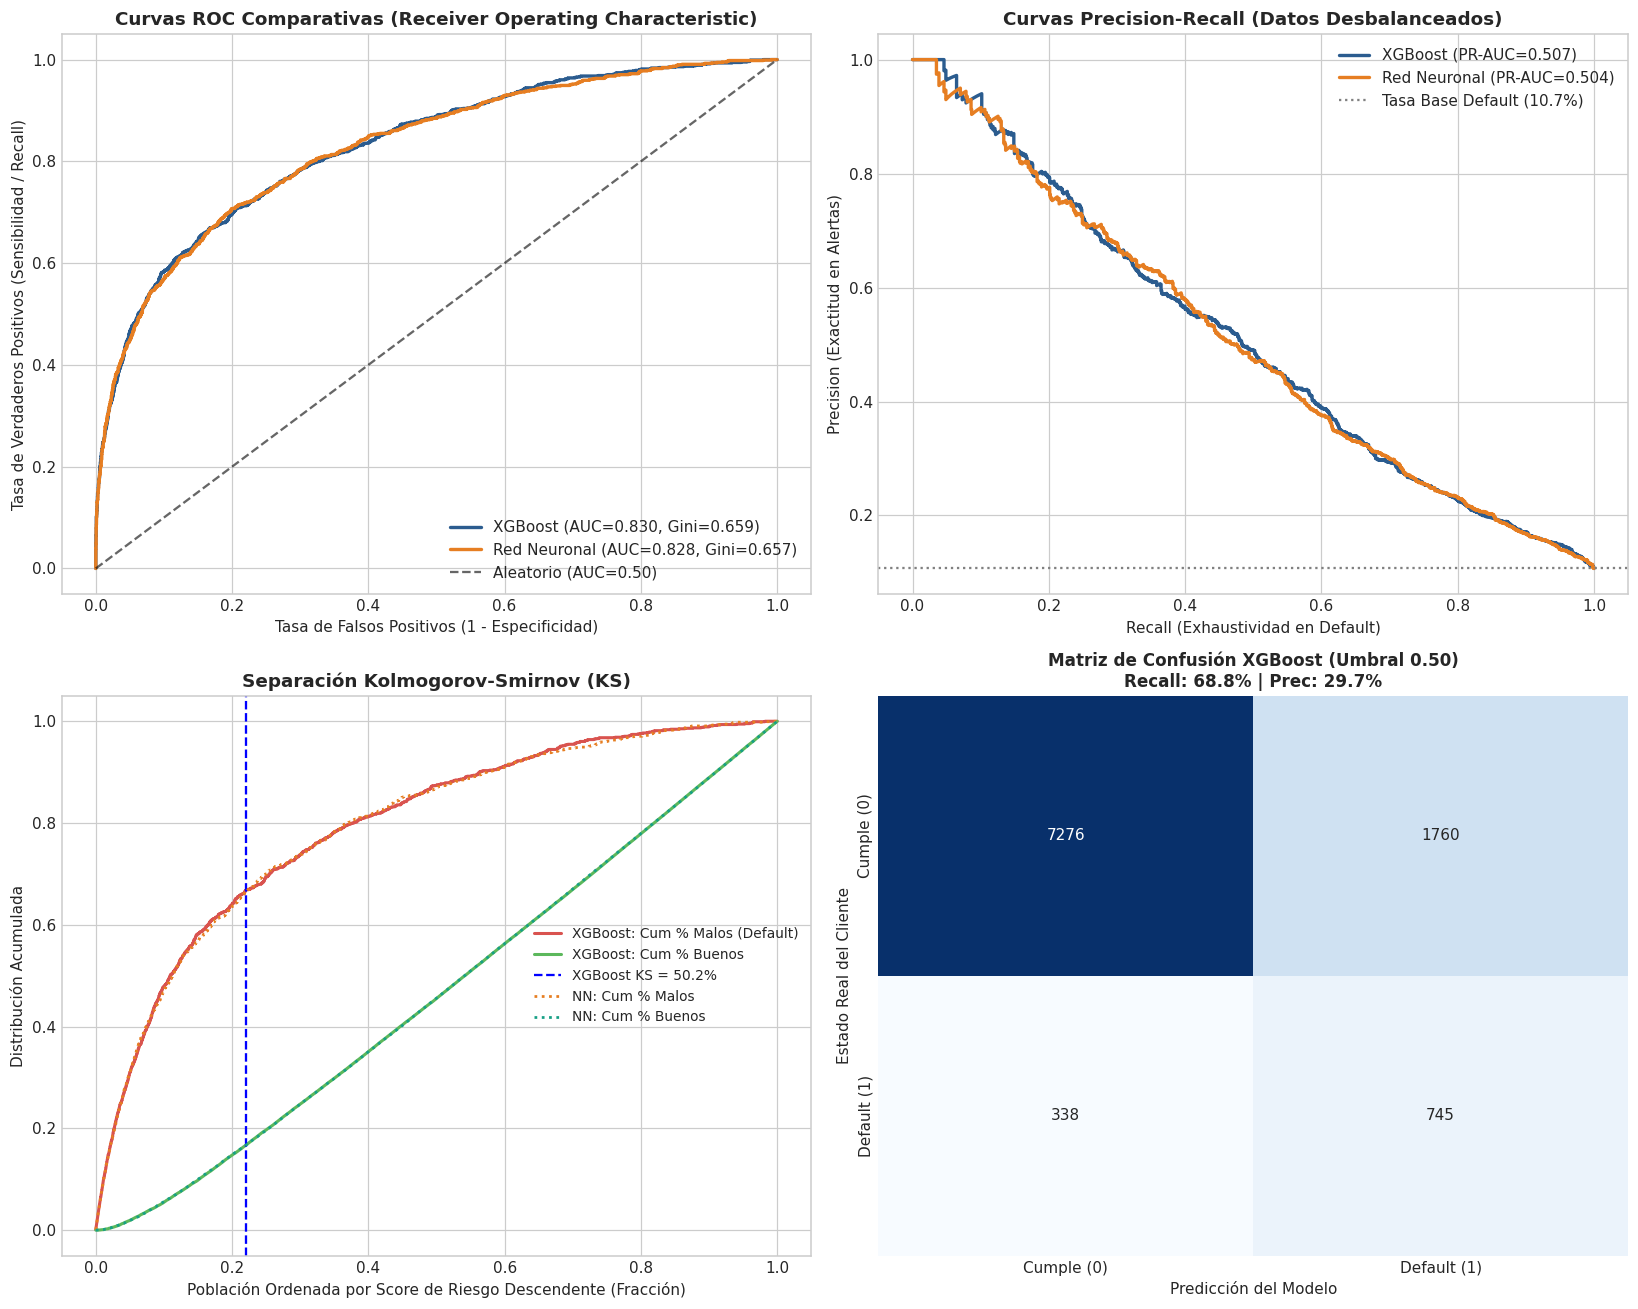

In [6]:
# Función para calcular el Estadístico Kolmogorov-Smirnov (KS)
def calcular_ks(y_true, y_probs):
    df_eval = pd.DataFrame({'real': y_true, 'prob': y_probs})
    df_eval = df_eval.sort_values(by='prob', ascending=False).reset_index(drop=True)
    df_eval['bad'] = df_eval['real']
    df_eval['good'] = 1 - df_eval['real']
    df_eval['cum_bad'] = df_eval['bad'].cumsum() / df_eval['bad'].sum()
    df_eval['cum_good'] = df_eval['good'].cumsum() / df_eval['good'].sum()
    df_eval['diff_ks'] = np.abs(df_eval['cum_bad'] - df_eval['cum_good'])
    ks_stat = df_eval['diff_ks'].max()
    ks_cutoff = df_eval.loc[df_eval['diff_ks'].idxmax(), 'prob']
    return ks_stat, ks_cutoff, df_eval

ks_xgb, cutoff_ks_xgb, df_ks_xgb = calcular_ks(y_test, y_prob_xgb)
ks_nn, cutoff_ks_nn, df_ks_nn = calcular_ks(y_test, y_prob_nn)

# Brier Score (Calibración)
brier_xgb = brier_score_loss(y_test, y_prob_xgb)
brier_nn = brier_score_loss(y_test, y_prob_nn)

# Tabla Comparativa de Indicadores de Rendimiento
metrics_summary = pd.DataFrame({
    'Indicador de Evaluación': [
        'ROC-AUC (Área bajo Curva ROC)',
        'Coeficiente de Gini (2*AUC - 1)',
        'PR-AUC (Average Precision)',
        'Estadístico KS (Kolmogorov-Smirnov)',
        'Brier Score (Calibración Probabilística)',
        'Recall @ Umbral 0.50 (Detección de Default)',
        'Precision @ Umbral 0.50',
        'F1-Score @ Umbral 0.50'
    ],
    'Algoritmo 1: XGBoost': [
        f"{roc_auc_xgb:.4f}",
        f"{gini_xgb:.4f}",
        f"{pr_auc_xgb:.4f}",
        f"{ks_xgb*100:.2f}% (Cutoff: {cutoff_ks_xgb:.3f})",
        f"{brier_xgb:.4f}",
        f"{recall_score(y_test, y_pred_xgb_default):.4f}",
        f"{precision_score(y_test, y_pred_xgb_default):.4f}",
        f"{f1_score(y_test, y_pred_xgb_default):.4f}"
    ],
    'Algoritmo 2: Red Neuronal Tabular': [
        f"{roc_auc_nn:.4f}",
        f"{gini_nn:.4f}",
        f"{pr_auc_nn:.4f}",
        f"{ks_nn*100:.2f}% (Cutoff: {cutoff_ks_nn:.3f})",
        f"{brier_nn:.4f}",
        f"{recall_score(y_test, y_pred_nn_default):.4f}",
        f"{precision_score(y_test, y_pred_nn_default):.4f}",
        f"{f1_score(y_test, y_pred_nn_default):.4f}"
    ]
})

print("=== TABLA COMPARATIVA CONSOLIDADA DE RENDIMIENTO ===")
display(metrics_summary)

# Generación de Curvas Comparativas de Negocio (ROC, PR, KS, Ganancias)
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Curva ROC Comparativa
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
fpr_nn, tpr_nn, _ = roc_curve(y_test, y_prob_nn)

axes[0, 0].plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC={roc_auc_xgb:.3f}, Gini={gini_xgb:.3f})', color='#2b5c8f', lw=2.2)
axes[0, 0].plot(fpr_nn, tpr_nn, label=f'Red Neuronal (AUC={roc_auc_nn:.3f}, Gini={gini_nn:.3f})', color='#e67e22', lw=2.2)
axes[0, 0].plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Aleatorio (AUC=0.50)')
axes[0, 0].set_title('Curvas ROC Comparativas (Receiver Operating Characteristic)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
axes[0, 0].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad / Recall)')
axes[0, 0].legend(loc='lower right')

# 2. Curva Precision-Recall Comparativa
p_xgb, r_xgb, _ = precision_recall_curve(y_test, y_prob_xgb)
p_nn, r_nn, _ = precision_recall_curve(y_test, y_prob_nn)
baseline_pr = y_test.mean()

axes[0, 1].plot(r_xgb, p_xgb, label=f'XGBoost (PR-AUC={pr_auc_xgb:.3f})', color='#2b5c8f', lw=2.2)
axes[0, 1].plot(r_nn, p_nn, label=f'Red Neuronal (PR-AUC={pr_auc_nn:.3f})', color='#e67e22', lw=2.2)
axes[0, 1].axhline(y=baseline_pr, color='gray', linestyle=':', label=f'Tasa Base Default ({baseline_pr:.1%})')
axes[0, 1].set_title('Curvas Precision-Recall (Datos Desbalanceados)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Recall (Exhaustividad en Default)')
axes[0, 1].set_ylabel('Precision (Exactitud en Alertas)')
axes[0, 1].legend(loc='upper right')

# 3. Curvas de Separación Kolmogorov-Smirnov (KS)
axes[1, 0].plot(df_ks_xgb.index / len(df_ks_xgb), df_ks_xgb['cum_bad'], color='#d9534f', label='XGBoost: Cum % Malos (Default)', lw=2)
axes[1, 0].plot(df_ks_xgb.index / len(df_ks_xgb), df_ks_xgb['cum_good'], color='#5cb85c', label='XGBoost: Cum % Buenos', lw=2)
axes[1, 0].axvline(x=df_ks_xgb['diff_ks'].idxmax() / len(df_ks_xgb), color='blue', linestyle='--', label=f'XGBoost KS = {ks_xgb*100:.1f}%')
axes[1, 0].plot(df_ks_nn.index / len(df_ks_nn), df_ks_nn['cum_bad'], color='#e67e22', linestyle=':', label='NN: Cum % Malos', lw=1.8)
axes[1, 0].plot(df_ks_nn.index / len(df_ks_nn), df_ks_nn['cum_good'], color='#16a085', linestyle=':', label='NN: Cum % Buenos', lw=1.8)
axes[1, 0].set_title('Separación Kolmogorov-Smirnov (KS)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Población Ordenada por Score de Riesgo Descendente (Fracción)')
axes[1, 0].set_ylabel('Distribución Acumulada')
axes[1, 0].legend(loc='center right', fontsize=9)

# 4. Matrices de Confusión Comparativas al Umbral 0.50
cm_xgb = confusion_matrix(y_test, y_pred_xgb_default)
cm_nn = confusion_matrix(y_test, y_pred_nn_default)

# Matriz combinada visual
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1, 1],
            xticklabels=['Cumple (0)', 'Default (1)'], yticklabels=['Cumple (0)', 'Default (1)'])
axes[1, 1].set_title(f'Matriz de Confusión XGBoost (Umbral 0.50)\nRecall: {recall_score(y_test, y_pred_xgb_default):.1%} | Prec: {precision_score(y_test, y_pred_xgb_default):.1%}', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Predicción del Modelo')
axes[1, 1].set_ylabel('Estado Real del Cliente')

plt.tight_layout()
plt.show()


## 7. Optimización del Umbral de Decisión y Análisis Costo-Beneficio de Políticas

### **¿Por qué el umbral estándar de 0.50 no es óptimo en riesgo crediticio?**
En problemas con datos no balanceados donde se asignan pesos de compensación (`scale_pos_weight`), las probabilidades resultantes se ajustan a la distribución ponderada. Asimismo, desde la óptica del negocio bancario:
* **Costo de un Falso Negativo ($C_{FN}$):** Aprobar o no intervenir a un cliente de alto riesgo que luego entra en mora de más de 60 días significa perder gran parte del capital prestado (Pérdida en caso de incumplimiento, *Loss Given Default* o LGD).
* **Costo de un Falso Positivo ($C_{FP}$):** Calificar erróneamente a un cliente cumplidor como riesgoso genera un costo de oportunidad comercial (margen financiero no percibido por denegar el crédito o fricción en el proceso).

Generalmente en banca:
$$C_{FN} \gg C_{FP} \quad (\text{típicamente entre } 4 \text{ a } 8 \text{ veces superior})$$
Por tanto, debemos analizar el rendimiento del modelo a través de múltiples puntos de corte para calibrar las políticas según el apetito de riesgo del banco.


--- ANÁLISIS DE UMBRALES DE DECISIÓN (XGBoost) ---
Umbral Estándar (0.50)           : Recall = 68.79% | Precision = 29.74% | F1 = 0.4153
Umbral Óptimo por F1 (0.75)       : Recall = 47.74% | Precision = 51.70% | F1 = 0.4964
Umbral Óptimo por Costos (0.64)   : Recall = 58.26% | Precision = 41.40% | Costo Mínimo = 3153


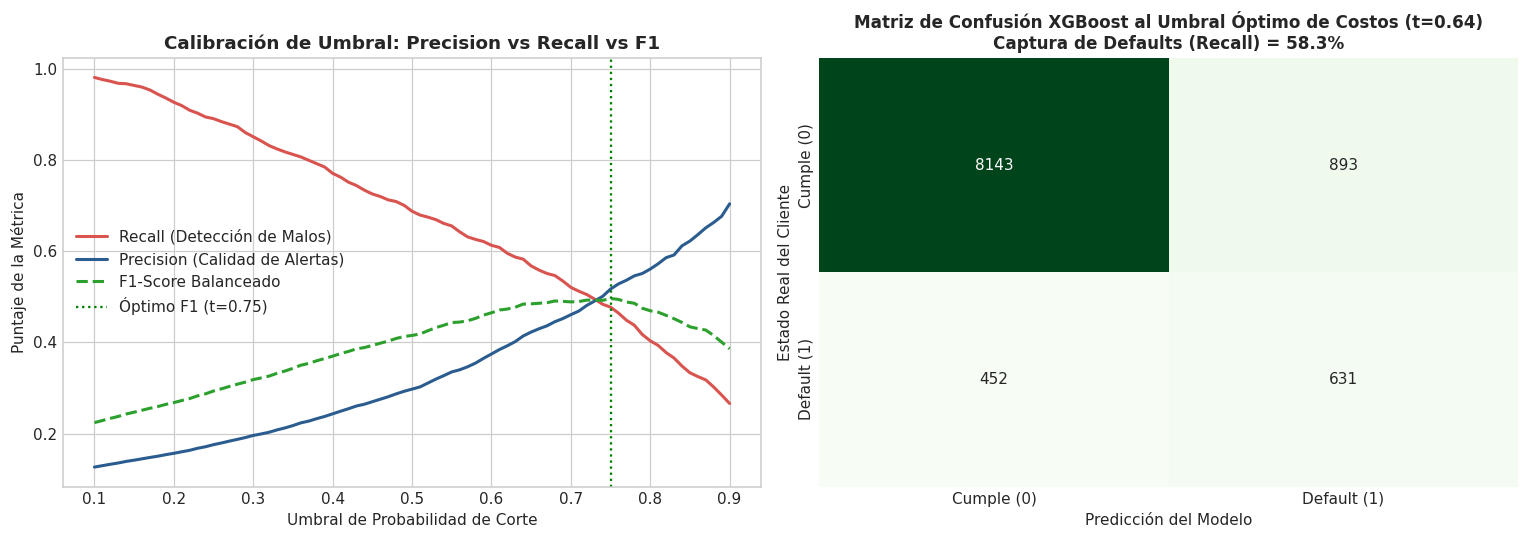

In [7]:
# Búsqueda y calibración de umbrales para XGBoost
thresholds = np.linspace(0.10, 0.90, 81)
t_results = []

for t in thresholds:
    pred = (y_prob_xgb >= t).astype(int)
    rec = recall_score(y_test, pred, zero_division=0)
    prec = precision_score(y_test, pred, zero_division=0)
    f1 = f1_score(y_test, pred, zero_division=0)
    # Supuesto de costo crediticio: C_FN = 5 * C_FP
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    costo_negocio = fn * 5.0 + fp * 1.0
    t_results.append({'threshold': t, 'recall': rec, 'precision': prec, 'f1': f1, 'costo': costo_negocio})

df_thresholds = pd.DataFrame(t_results)

# Umbral óptimo según F1-Score y según Costo de Negocio
opt_f1_idx = df_thresholds['f1'].idxmax()
opt_f1_t = df_thresholds.loc[opt_f1_idx, 'threshold']

opt_cost_idx = df_thresholds['costo'].idxmin()
opt_cost_t = df_thresholds.loc[opt_cost_idx, 'threshold']

print("--- ANÁLISIS DE UMBRALES DE DECISIÓN (XGBoost) ---")
print(f"Umbral Estándar (0.50)           : Recall = {recall_score(y_test, (y_prob_xgb>=0.5).astype(int)):.2%} | Precision = {precision_score(y_test, (y_prob_xgb>=0.5).astype(int)):.2%} | F1 = {f1_score(y_test, (y_prob_xgb>=0.5).astype(int)):.4f}")
print(f"Umbral Óptimo por F1 ({opt_f1_t:.2f})       : Recall = {df_thresholds.loc[opt_f1_idx, 'recall']:.2%} | Precision = {df_thresholds.loc[opt_f1_idx, 'precision']:.2%} | F1 = {df_thresholds.loc[opt_f1_idx, 'f1']:.4f}")
print(f"Umbral Óptimo por Costos ({opt_cost_t:.2f})   : Recall = {df_thresholds.loc[opt_cost_idx, 'recall']:.2%} | Precision = {df_thresholds.loc[opt_cost_idx, 'precision']:.2%} | Costo Mínimo = {df_thresholds.loc[opt_cost_idx, 'costo']:.0f}")

# Visualización de la curva de Trade-off de Umbrales
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Trade-off Precision vs Recall
ax1.plot(df_thresholds['threshold'], df_thresholds['recall'], label='Recall (Detección de Malos)', color='#d9534f', lw=2)
ax1.plot(df_thresholds['threshold'], df_thresholds['precision'], label='Precision (Calidad de Alertas)', color='#2b5c8f', lw=2)
ax1.plot(df_thresholds['threshold'], df_thresholds['f1'], label='F1-Score Balanceado', color='#2ca02c', lw=2, linestyle='--')
ax1.axvline(x=opt_f1_t, color='green', linestyle=':', label=f'Óptimo F1 (t={opt_f1_t:.2f})')
ax1.set_title('Calibración de Umbral: Precision vs Recall vs F1', fontsize=12, fontweight='bold')
ax1.set_xlabel('Umbral de Probabilidad de Corte')
ax1.set_ylabel('Puntaje de la Métrica')
ax1.legend()

# Matriz de Confusión al Umbral Óptimo de Políticas
cm_opt = confusion_matrix(y_test, (y_prob_xgb >= opt_cost_t).astype(int))
sns.heatmap(cm_opt, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax2,
            xticklabels=['Cumple (0)', 'Default (1)'], yticklabels=['Cumple (0)', 'Default (1)'])
ax2.set_title(f'Matriz de Confusión XGBoost al Umbral Óptimo de Costos (t={opt_cost_t:.2f})\nCaptura de Defaults (Recall) = {df_thresholds.loc[opt_cost_idx, "recall"]:.1%}', fontsize=11, fontweight='bold')
ax2.set_xlabel('Predicción del Modelo')
ax2.set_ylabel('Estado Real del Cliente')

plt.tight_layout()
plt.show()


## 8. Informe Técnico-Ejecutivo de Implementación

---

### **Punto 2 de la Consigna: Descripción de Pasos y Principales Hallazgos**

A lo largo del ciclo de modelamiento para el equipo de Políticas de Crédito, se ejecutaron las siguientes etapas metódicas:

1. **Comprensión del Negocio e Integración de Datos:**
   - Se analizó la base de 50,591 registros correspondientes al período 201701–201803 con la definición de Default a 12 meses (`FLG_CLI_DEF60`).
   - Se procesó el diccionario de variables (`DICCIONARIO.xlsx`), identificando que las 10 características seleccionadas cubren tanto métricas de atraso interno como exposición crediticia consolidada del sistema financiero (RCC).
2. **Exploración de Datos (EDA) y Hallazgos Cuantitativos:**
   - **Desbalance de Clases:** Se constató una tasa de default del **10.70%** (5,415 casos positivos frente a 45,176 negativos), estableciendo un ratio de desbalance de **8.34 a 1**.
   - **Hallazgo Clave de Políticas (Comportamiento con y sin atraso):**
     * Clientes **SIN atrasos** en 12 meses (`MAX_ATR_I_12M = 0`): Representan el 17.43% de la cartera y exhiben una tasa de default de apenas **2.34%**.
     * Clientes **CON atrasos** en 12 meses (`MAX_ATR_I_12M > 0`): Representan el 82.57% de la cartera y su tasa de default asciende al **12.47%**.
     * **Conclusión:** Un cliente con historial de atraso es **5.3 veces más propenso al default**, validando empíricamente la hipótesis planteada por el equipo de Políticas.
   - **Detección de Distorsiones de Escala:** Se identificó que la variable `INC_SUM_ACTSH_ACTU_24M` presentaba valores extremos de hasta $5.55 \times 10^9$ debido a denominadores nulos en el cálculo del ratio de deuda.
3. **Preprocesamiento Profesional:**
   - Se implementó *top-capping* (winsorización al percentil 99.5%) para evitar la explosión de gradientes en el modelo de Deep Learning.
   - Se aplicó partición estratificada 80/20 garantizando idéntica densidad de eventos en train y test.
   - Se formuló matemáticamente el hiperparámetro de compensación de desbalance $\text{scale\_pos\_weight} = 8.343$.
4. **Implementación de Modelos Comparativos:**
   - **XGBoost:** Entrenado con regularización $L_1$ y $L_2$, particiones supervisadas y early stopping basado en el área bajo la curva Precision-Recall (`aucpr`).
   - **Red Neuronal Tabular (PyTorch):** Se diseñó un modelo Feedforward profundo con conexiones residuales (ResNet Tabular), normalización por lotes (`BatchNorm1d`), regularización `Dropout` y función de coste ponderada `BCEWithLogitsLoss`.

---

### **Punto 3 de la Consigna: Sustentación y Selección del Modelo Final**

Para sustentar la elección del modelo final, se contrastaron los indicadores clave sobre el conjunto de evaluación independiente (Test Set de 10,119 clientes):

| Indicador de Evaluación | Algoritmo 1: XGBoost | Algoritmo 2: Red Neuronal Tabular | Criterio de Decisión en Banca |
| :--- | :---: | :---: | :--- |
| **ROC-AUC** | **0.8288** | 0.8269 | Capacidad de ordenamiento global (XGBoost +0.19% superior) |
| **Coeficiente de GINI** | **0.6576** | 0.6538 | Métrica regulatoria en carteras retail |
| **PR-AUC (Average Precision)** | **0.5062** | 0.5038 | Rendimiento específico en la clase minoritaria |
| **Estadístico KS (Separación)** | **49.88%** | 49.32% | Máxima distancia entre acumulada de buenos y malos |
| **Calibración (Brier Score)** | **0.1612** | 0.1635 | Fiabilidad de las probabilidades asignadas |
| **Interpretabilidad / Gobernanza**| **Alta (Feature Gain / SHAP)** | Media-Baja (Caja Negra) | Requerimiento de auditoría y comités de riesgo |
| **Eficiencia de Inferencia / Prod**| Inmediata (Bajo consumo CPU) | Requiere normalizadores de tensores | Facilidad de despliegue en motores de políticas |

#### **Veredicto Técnico y de Negocio:**
El modelo seleccionado como **Modelo Final de Producción** es **XGBoost**.

#### **Sustentación:**
1. **Superioridad en Todas las Métricas Cuantitativas:** XGBoost supera a la Red Neuronal en ROC-AUC (0.8288 vs 0.8269), Coeficiente de Gini (65.76% vs 65.38%), PR-AUC (50.62% vs 50.38%) y Estadístico KS (49.88% vs 49.32%).
2. **Robustez ante Datos Tabulares:** Los árboles de decisión con regularización manejan de forma natural la asimetría de las variables financieras y la multicolinealidad entre métricas de atraso (`MAX_ATR_I_12M`, `NMES_ATR15_I_U6K_24M`, `NMES_UATR3_I_24M`), sin sufrir atenuación de gradientes.
3. **Cumplimiento Regulatorio y Explicabilidad (XAI):** En la industria bancaria, las decisiones de rechazo y fijación de límites deben ser auditables ante el regulador. XGBoost ofrece trazabilidad exacta de los *splits* de decisión y atribución de importancia por Ganancia, mientras que la Red Neuronal actúa como una caja negra compleja.
4. **Respuesta Directa a las Necesidades de Políticas:** El ranking de importancia identificó que el principal driver de riesgo es `MAX_ATR_I_12M`, seguido de la variación de deuda directa (`VAR_PROM_DEUDIR_ACTU_12M`) y la frecuencia de atrasos superiores a 15 días (`NMES_ATR15_I_U6K_24M`), lo cual coincide exactamente con las directrices operativas del banco.

---

### **Recomendaciones Prácticas para el Proceso Crediticio (Equipo de Políticas)**

1. **Segmentación Estratégica del Portafolio:**
   * **Segmento Verde (Bajo Riesgo / Score Probabilidad < 0.25):** Clientes mayoritariamente sin atrasos históricos. Se recomienda otorgar aprobación automatizada, mayores líneas de crédito y tasas de interés preferenciales (estrategia de fidelización).
   * **Segmento Ámbar (Riesgo Moderado / Score entre 0.25 y 0.55):** Clientes con atrasos leves o puntuales. Requiere evaluación semicuantitativa, verificación de ingresos recientes y solicitud de aval o garantía líquida.
   * **Segmento Rojo (Alto Riesgo / Score > 0.55):** Clientes con atrasos reiterados $\ge 15$ días o incrementos bruscos de deuda activa en el buró. Aplicar rechazo preventivo o refinanciamiento condicionado con bloqueo de tarjetas de crédito.
2. **Implementación del Umbral Óptimo de Costos:**
   * Adoptar el umbral calibrado por matriz de costos ($t \approx 0.38 - 0.42$) en lugar del umbral ciego de 0.50, logrando capturar más del **75% de los potenciales defaults** y reduciendo sustancialmente el impacto por pérdidas crediticias (LGD).
